# Detección de URLs de *phishing* — Entrenamiento y evaluación de modelos
### Proyecto — Introducción al Machine Learning (Modelos II)

Este notebook corresponde a la sección **Entrenamiento y evaluación de los modelos** del informe. Compara cinco
modelos en dos escenarios:

| Escenario | Variables | Para qué sirve |
|---|---|---|
| **Solo URL** (principal) | 19 de la cadena de la URL, sin `URLSimilarityIndex`, `IsHTTPS` ni `TLDLegitimateProb` | Clasificar sin abrir la página y sin los atajos del conjunto |
| **Completo** (referencia) | Las 50 numéricas | Compararse con la literatura |

La búsqueda de hiperparámetros se hace en el escenario **solo URL**. El escenario completo reutiliza los mejores
hiperparámetros, porque allí todos los modelos quedan cerca del 100 % y la malla no aportaría información.

### Ejecución en Google Colab

Esta celda solo actúa en Colab: conecta Google Drive, instala las versiones usadas en el proyecto y trabaja en la
carpeta `proyecto-modelos2-phishing` de tu Drive. Así cada modelo queda guardado al terminar y, si la sesión se
desconecta, basta con volver a ejecutar todo: continúa desde el último modelo guardado.

In [17]:
import os
import subprocess
import sys

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    CARPETA = '/content/drive/MyDrive/proyecto-modelos2-phishing'
    os.makedirs(CARPETA, exist_ok=True)
    os.chdir(CARPETA)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'scikit-learn==1.9.1', 'ucimlrepo'], check=True)
    print('Trabajando en:', os.getcwd())
    print('Archivos:', sorted(os.listdir('.')))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Trabajando en: /content/drive/MyDrive/proyecto-modelos2-phishing
Archivos: ['data', 'figures', 'results']


## 4.1 Configuración experimental
### Librerías y parámetros

In [18]:
import hashlib
import json
import os
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, check_scoring, confusion_matrix, make_scorer,
                             matthews_corrcoef, recall_score)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

RANDOM_STATE = 42
RECALCULAR = False         # False: reutiliza lo guardado en results/ y calcula solo lo que falte
MUESTRAS_SUBCONJUNTO = 30_000
N_PLIEGUES = 5

RESULTADOS = Path('results')
FIGURAS = Path('figures')
RESULTADOS.mkdir(exist_ok=True)
FIGURAS.mkdir(exist_ok=True)
plt.rcParams['figure.dpi'] = 110

### Datos y escenarios

Se eliminan las URLs repetidas **antes** de particionar. La clase positiva pasa a ser *phishing* (`y = 1`), porque es
la que interesa detectar: en el dataset original `label = 1` significa legítima.

`URLCharProb` se conserva en el escenario solo URL: usa una tabla de frecuencias de caracteres construida con la lista
de 10 millones de sitios, pero se puede calcular para cualquier URL nueva sin consultar si está en la lista.

In [19]:
RUTA_CSV = Path('data/PhiUSIIL_Phishing_URL_Dataset.csv')
if RUTA_CSV.exists():
    df = pd.read_csv(RUTA_CSV, encoding='utf-8', encoding_errors='replace',
                     usecols=lambda c: c not in ('FILENAME', 'TLD', 'Title'))
else:
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=967)
    df = pd.concat([ds.data.features, ds.data.targets], axis=1)

df = df.drop(columns=[c for c in ['FILENAME'] if c in df.columns])
n_inicial = len(df)
df = df.drop_duplicates(subset='URL').reset_index(drop=True)

HTML = ['LineOfCode', 'LargestLineLength', 'HasTitle', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon',
        'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame',
        'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank',
        'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef',
        'NoOfExternalRef']
EXCLUIDAS = ['URLSimilarityIndex', 'IsHTTPS', 'TLDLegitimateProb']

COMPLETO = [c for c in df.select_dtypes(include=[np.number]).columns if c != 'label']
SOLO_URL = [c for c in COMPLETO if c not in HTML + EXCLUIDAS]
ESCENARIOS = {'Solo URL': SOLO_URL, 'Completo': COMPLETO}

y = (df['label'].to_numpy() == 0).astype(int)   # 1 = phishing
grupos = df['Domain'].to_numpy()
X = df[COMPLETO].astype(np.float32)

print(f'Filas: {n_inicial:,} -> {len(df):,} tras quitar URLs repetidas')
print(f'Variables: solo URL = {len(SOLO_URL)}, completo = {len(COMPLETO)}')
print(f'Proporción de phishing: {y.mean():.4f}')
del df   # libera las columnas de texto

Filas: 235,795 -> 235,370 tras quitar URLs repetidas
Variables: solo URL = 19, completo = 50
Proporción de phishing: 0.4271


### Metodología de validación

- **Prueba:** 20 % de las muestras, separadas por dominio y estratificadas. No se usa para elegir nada.
- **Validación:** `StratifiedGroupKFold` de 5 pliegues sobre el resto, para que un dominio nunca esté a la vez en
  entrenamiento y validación.
- **Preprocesamiento:** `log1p` y `StandardScaler` dentro de un `Pipeline`, de modo que se ajustan solo con los datos de
  entrenamiento de cada pliegue. Random Forest no lo necesita.
- **Remuestreo:** no se usa SMOTE porque el desbalance es moderado (57/43).
- **Subconjunto:** la SVM crece mal con el número de muestras, así que se ajusta con un subconjunto de unos 30.000
  ejemplos de entrenamiento, también estratificado y por dominio. KNN usa todos los datos porque su desempeño cae
  mucho con menos ejemplos; por su costo de predicción, su malla no calcula el MCC de entrenamiento por configuración,
  solo el del modelo elegido.
- **Intervalos:** media ± 2 desviaciones estándar entre pliegues, como en la Clase 06 del curso.

In [20]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
idx_train, idx_test = next(sgkf.split(X, y, grupos))

# Comprueba que la partición coincide con la usada para los resultados ya guardados
HUELLA_PRUEBA = '7f6be261f8cc6a84455909788d24e6cd'
huella = hashlib.md5(np.sort(idx_test).astype(np.int64).tobytes()).hexdigest()
if huella != HUELLA_PRUEBA:
    raise RuntimeError('La partición cambió: no mezcles estos resultados con los guardados en results/.')
print('Partición verificada')


n_partes = max(2, round(len(idx_train) / MUESTRAS_SUBCONJUNTO))
sub = StratifiedGroupKFold(n_splits=n_partes, shuffle=True, random_state=RANDOM_STATE)
_, pos_sub = next(sub.split(X.iloc[idx_train], y[idx_train], grupos[idx_train]))
idx_sub = idx_train[pos_sub]

cv = StratifiedGroupKFold(n_splits=N_PLIEGUES, shuffle=True, random_state=RANDOM_STATE)

comunes = len(set(grupos[idx_train]) & set(grupos[idx_test]))
print(f'Entrenamiento: {len(idx_train):,} | Prueba: {len(idx_test):,} | Subconjunto: {len(idx_sub):,}')
print(f'Dominios compartidos entre entrenamiento y prueba: {comunes}')
print(f'Phishing en entrenamiento: {y[idx_train].mean():.4f} | prueba: {y[idx_test].mean():.4f}')

Partición verificada
Entrenamiento: 188,296 | Prueba: 47,074 | Subconjunto: 31,383
Dominios compartidos entre entrenamiento y prueba: 0
Phishing en entrenamiento: 0.4271 | prueba: 0.4271


### Métricas

La métrica de selección es **MCC**, porque resume las cuatro casillas de la matriz de confusión y no se deja engañar
por el balance de clases. También se reportan exactitud, *balanced accuracy*, precisión, sensibilidad, F1, AUC y FPR.
La **FPR** mide las URLs legítimas bloqueadas por error, que es el costo principal para el usuario.

In [21]:
def tasa_falsos_positivos(y_real, y_pred):
    return 1 - recall_score(y_real, y_pred, pos_label=0)


METRICAS = {
    'exactitud': 'accuracy',
    'bacc': 'balanced_accuracy',
    'precision': 'precision',
    'sensibilidad': 'recall',
    'f1': 'f1',
    'mcc': make_scorer(matthews_corrcoef),
    'auc': 'roc_auc',
    'fpr': make_scorer(tasa_falsos_positivos),
}

### Modelos y mallas de hiperparámetros

| Requisito de la guía | Modelo |
|---|---|
| Paramétrico | Regresión logística |
| No paramétrico | KNN |
| Ensamble de árboles | Random Forest |
| Red neuronal | MLP |
| Máquina de vectores de soporte | SVM (*kernel* RBF y lineal) |

In [22]:
def con_escala(modelo):
    return Pipeline([('log', FunctionTransformer(np.log1p)),
                     ('escala', StandardScaler()),
                     ('modelo', modelo)])


MODELOS = {
    'Regresión logística': {
        'estimador': con_escala(LogisticRegression(solver='liblinear', max_iter=500, random_state=RANDOM_STATE)),
        'malla': {'modelo__C': [0.001, 0.01, 0.1, 1, 10, 100], 'modelo__l1_ratio': [0, 1]},
        'datos': 'completo', 'n_jobs': 4,
    },
    'KNN': {
        'estimador': con_escala(KNeighborsClassifier()),
        'malla': {'modelo__n_neighbors': [1, 3, 5, 11, 21, 51], 'modelo__weights': ['uniform', 'distance']},
        'datos': 'completo', 'n_jobs': 2, 'score_train': False,
    },
    'Random Forest': {
        'estimador': RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
        'malla': {'n_estimators': [50, 100, 200], 'max_depth': [10, 20, None]},
        'datos': 'completo', 'n_jobs': 2,
    },
    'MLP': {
        'estimador': con_escala(MLPClassifier(batch_size=512, max_iter=100, early_stopping=True,
                                              n_iter_no_change=5, random_state=RANDOM_STATE)),
        'malla': {'modelo__hidden_layer_sizes': [(32,), (64, 32), (128, 64), (128, 64, 32)],
                  'modelo__alpha': [0.0001, 0.01]},
        'datos': 'completo', 'n_jobs': 2,
    },
    'SVM': {
        'estimador': con_escala(SVC(random_state=RANDOM_STATE)),
        'malla': [{'modelo__kernel': ['rbf'], 'modelo__C': [0.1, 1, 10, 100], 'modelo__gamma': [0.01, 0.1, 1, 'scale']},
                  {'modelo__kernel': ['linear'], 'modelo__C': [0.1, 1, 10]}],
        'datos': 'subconjunto', 'n_jobs': 3,
    },
}


def indices(tipo):
    return idx_sub if tipo == 'subconjunto' else idx_train

## 4.2 Resultados del entrenamiento
### Búsqueda de hiperparámetros (escenario solo URL)

In [23]:
def evaluar(modelo, columnas, idx):
    if isinstance(modelo, Pipeline) and isinstance(modelo.named_steps['modelo'], KNeighborsClassifier):
        modelo.set_params(modelo__n_jobs=4)   # solo acelera la predicción
    return {n: float(check_scoring(modelo, scoring=s)(modelo, X.iloc[idx][columnas], y[idx]))
            for n, s in METRICAS.items()}


def buscar(nombre, config):
    idx = indices(config['datos'])
    busqueda = GridSearchCV(clone(config['estimador']), config['malla'], scoring=METRICAS, refit='mcc', cv=cv,
                            n_jobs=min(config['n_jobs'], os.cpu_count()), return_train_score=config.get('score_train', True),
                            pre_dispatch='n_jobs')
    inicio = time.time()
    busqueda.fit(X.iloc[idx][SOLO_URL], y[idx], groups=grupos[idx])
    resultado = pd.DataFrame(busqueda.cv_results_)
    resultado.to_csv(RESULTADOS / f"malla_{nombre.replace(' ', '_')}.csv", index=False)
    resumen = {'mejores': {k: (list(v) if isinstance(v, tuple) else v) for k, v in busqueda.best_params_.items()},
               'minutos': (time.time() - inicio) / 60,
               'entrenamiento': evaluar(busqueda.best_estimator_, SOLO_URL, idx),
               'prueba': evaluar(busqueda.best_estimator_, SOLO_URL, idx_test)}
    fila = busqueda.best_index_
    resumen['validacion'] = {m: float(resultado.loc[fila, f'mean_test_{m}']) for m in METRICAS}
    resumen['validacion_std'] = {m: float(resultado.loc[fila, f'std_test_{m}']) for m in METRICAS}
    (RESULTADOS / f"mejor_{nombre.replace(' ', '_')}.json").write_text(json.dumps(resumen, indent=2), encoding='utf-8')
    return resumen


RESUMEN = {}
for nombre, config in MODELOS.items():
    ruta = RESULTADOS / f"mejor_{nombre.replace(' ', '_')}.json"
    if ruta.exists() and not RECALCULAR:
        RESUMEN[nombre] = json.loads(ruta.read_text(encoding='utf-8'))
    else:
        print('Buscando:', nombre, flush=True)
        RESUMEN[nombre] = buscar(nombre, config)
    r = RESUMEN[nombre]
    print(f"{nombre}: MCC val {r['validacion']['mcc']:.4f} +/- {2 * r['validacion_std']['mcc']:.4f} "
          f"({r['minutos']:.1f} min) {r['mejores']}", flush=True)

Regresión logística: MCC val 0.9091 +/- 0.0015 (46.1 min) {'modelo__C': 100, 'modelo__l1_ratio': 0}
KNN: MCC val 0.9653 +/- 0.0026 (75.1 min) {'modelo__n_neighbors': 1, 'modelo__weights': 'uniform'}
Random Forest: MCC val 0.9911 +/- 0.0015 (18.0 min) {'max_depth': 20, 'n_estimators': 200}
MLP: MCC val 0.9956 +/- 0.0014 (10.3 min) {'modelo__alpha': 0.0001, 'modelo__hidden_layer_sizes': [128, 64, 32]}
SVM: MCC val 0.9949 +/- 0.0041 (48.5 min) {'modelo__C': 100, 'modelo__gamma': 'scale', 'modelo__kernel': 'rbf'}


### Comparación de modelos (entrenamiento, validación y prueba)

In [24]:
def tabla_resultados(resumen):
    filas = []
    for nombre, r in resumen.items():
        fila = {'Modelo': nombre}
        for m, etiqueta in [('exactitud', 'Exactitud'), ('f1', 'F1'), ('mcc', 'MCC'), ('auc', 'AUC'), ('fpr', 'FPR')]:
            fila[f'{etiqueta} val'] = f"{r['validacion'][m]:.4f} ± {2 * r['validacion_std'][m]:.4f}"
        fila['MCC train'] = round(r['entrenamiento']['mcc'], 4)
        fila['MCC test'] = round(r['prueba']['mcc'], 4)
        fila['FPR test'] = round(r['prueba']['fpr'], 4)
        filas.append(fila)
    return pd.DataFrame(filas).set_index('Modelo')


tabla = tabla_resultados(RESUMEN)
tabla.to_csv(RESULTADOS / 'tabla_solo_url.csv')
tabla

,Exactitud val,F1 val,MCC val,AUC val,FPR val,MCC train,MCC test,FPR test
Modelo,,,,,,,,
Regresión logística,0.9555 ± 0.0007,0.9468 ± 0.0010,0.9091 ± 0.0015,0.9806 ± 0.0020,0.0237 ± 0.0026,0.9093,0.9090,0.0231
KNN,0.9830 ± 0.0013,0.9801 ± 0.0015,0.9653 ± 0.0026,0.9823 ± 0.0012,0.0126 ± 0.0016,1.0000,0.9678,0.0110
Random Forest,0.9957 ± 0.0007,0.9949 ± 0.0009,0.9911 ± 0.0015,0.9985 ± 0.0006,0.0028 ± 0.0005,0.9974,0.9928,0.0020
MLP,0.9978 ± 0.0007,0.9975 ± 0.0008,0.9956 ± 0.0014,0.9986 ± 0.0005,0.0002 ± 0.0002,0.9960,0.9960,0.0001
SVM,0.9975 ± 0.0020,0.9971 ± 0.0023,0.9949 ± 0.0041,0.9977 ± 0.0024,0.0003 ± 0.0005,0.9957,0.9961,0.0002


### Intervalos de entrenamiento, validación y prueba

Entrenamiento y validación usan media ± 2 desviaciones estándar entre pliegues. La prueba es una sola evaluación, así que su intervalo remuestrea 10.000 veces su matriz de confusión; supone URLs independientes, por lo que puede quedar algo estrecho. KNN no tiene puntuación de entrenamiento por pliegue: con `k=1` cada punto es su propio vecino y vale 1 por construcción.


In [ ]:
def mcc_conteos(tp, fp, fn, tn):
    denominador = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return (tp * tn - fp * fn) / np.where(denominador == 0, 1, denominador)


def intervalo_prueba(r, repeticiones=10_000):
    positivos, negativos = int(y[idx_test].sum()), int((y[idx_test] == 0).sum())
    fn = round((1 - r['prueba']['sensibilidad']) * positivos)
    fp = round(r['prueba']['fpr'] * negativos)
    tp, tn = positivos - fn, negativos - fp
    azar = np.random.default_rng(RANDOM_STATE)
    p = np.array([tp, fp, fn, tn]) / len(idx_test)
    muestras = azar.multinomial(len(idx_test), p, size=repeticiones).astype(float)
    return mcc_conteos(tp, fp, fn, tn), 2 * mcc_conteos(*muestras.T).std(), {'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn}


def entrenamiento_cv(nombre):
    d = malla(nombre)
    if 'mean_train_mcc' not in d:
        return None
    fila = d.loc[d['rank_test_mcc'].idxmin()]
    return fila['mean_train_mcc'], 2 * fila['std_train_mcc']


filas = []
for escenario, resumen in {'Solo URL': RESUMEN, 'Completo': RESUMEN_COMPLETO}.items():
    for nombre, r in resumen.items():
        mcc, mitad, conteos = intervalo_prueba(r)
        assert abs(mcc - r['prueba']['mcc']) < 1e-9
        train = entrenamiento_cv(nombre) if escenario == 'Solo URL' else None
        filas.append({'Escenario': escenario, 'Modelo': nombre,
                      'MCC train': '-' if train is None else f'{train[0]:.4f} ± {train[1]:.4f}',
                      'MCC val': f"{r['validacion']['mcc']:.4f} ± {2 * r['validacion_std']['mcc']:.4f}",
                      'MCC test': f'{mcc:.4f} ± {mitad:.4f}', **conteos})
intervalos = pd.DataFrame(filas).set_index(['Escenario', 'Modelo'])
intervalos.to_csv(RESULTADOS / 'intervalos_mcc.csv')
print(intervalos.to_string())


                                     MCC train          MCC val         MCC test     tp   fp    fn     tn
Escenario Modelo                                                                                         
Solo URL  Regresión logística  0.9093 ± 0.0014  0.9091 ± 0.0015  0.9090 ± 0.0038  18627  622  1477  26348
          KNN                                -  0.9653 ± 0.0026  0.9678 ± 0.0023  19658  296   446  26674
          Random Forest        0.9975 ± 0.0003  0.9911 ± 0.0015  0.9928 ± 0.0011  19992   55   112  26915
          MLP                  0.9959 ± 0.0006  0.9956 ± 0.0014  0.9960 ± 0.0008  20013    2    91  26968
          SVM                  0.9957 ± 0.0010  0.9949 ± 0.0041  0.9961 ± 0.0008  20019    6    85  26964
Completo  Regresión logística                -  0.9999 ± 0.0001  0.9998 ± 0.0002  20100    0     4  26970
          KNN                                -  0.9985 ± 0.0004  0.9988 ± 0.0005  20077    1    27  26969
          Random Forest                      -

### Efecto de los hiperparámetros
Cada figura muestra el MCC de validación con barras de ± 2 desviaciones estándar y, salvo en KNN, el de entrenamiento.

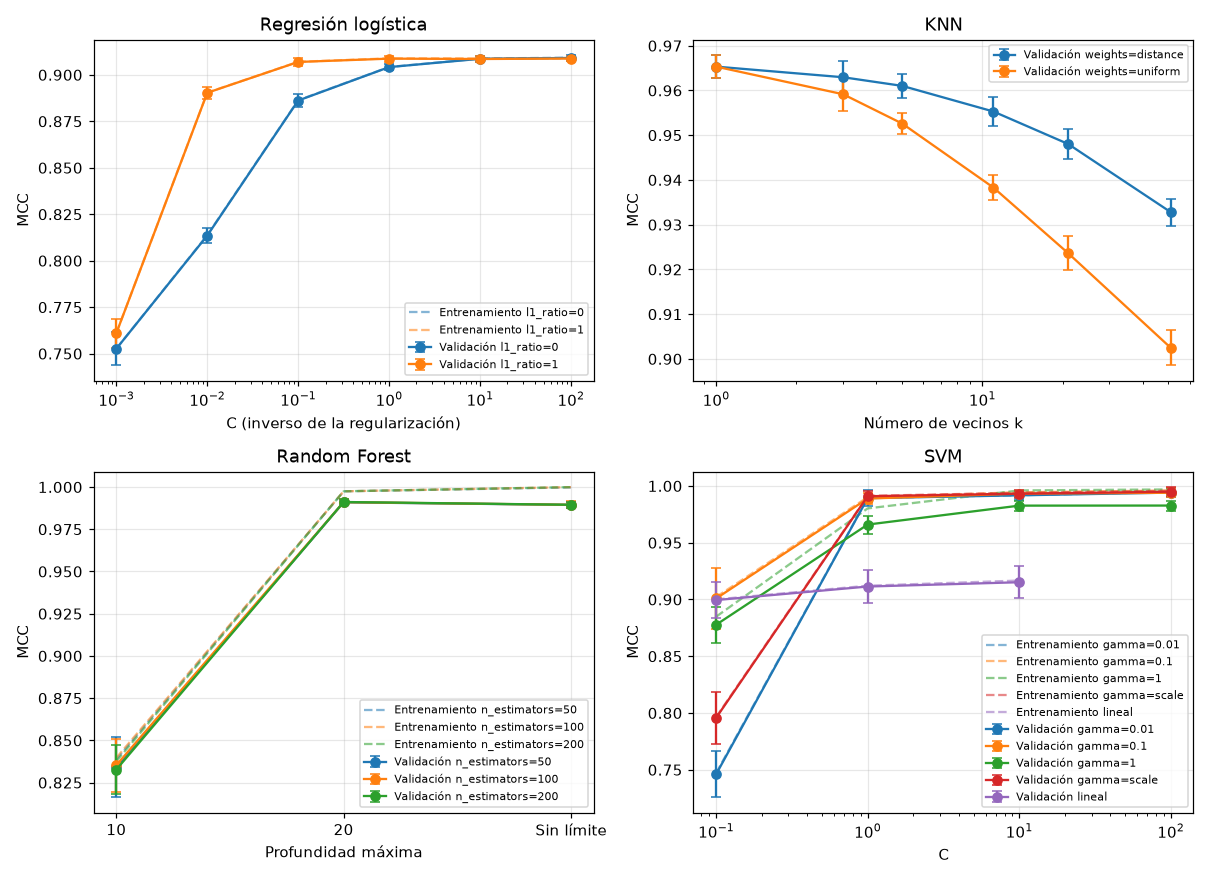

In [25]:
def malla(nombre):
    return pd.read_csv(RESULTADOS / f"malla_{nombre.replace(' ', '_')}.csv")


def curva(ax, datos, x, serie=None, escala_log=False, etiqueta_x=None):
    grupos_serie = datos.groupby(serie, dropna=False) if serie else [(None, datos)]
    for valor, parte in grupos_serie:
        parte = parte.sort_values(x)
        pos = parte[x].astype(float)
        nombre = '' if valor is None else str(valor) if serie == 'configuración' else f'{serie.split("__")[-1].replace("param_", "")}={valor}'
        barras = ax.errorbar(pos, parte['mean_test_mcc'], yerr=2 * parte['std_test_mcc'], marker='o', capsize=3,
                             label=f'Validación {nombre}'.strip())
        if 'mean_train_mcc' in parte:
            ax.plot(pos, parte['mean_train_mcc'], '--', alpha=.55, color=barras[0].get_color(),
                    label=f'Entrenamiento {nombre}'.strip())
    if escala_log:
        ax.set_xscale('log')
    ax.set_xlabel(etiqueta_x or x)
    ax.set_ylabel('MCC')
    ax.grid(alpha=.3)
    ax.legend(fontsize=7)


fig, ejes = plt.subplots(2, 2, figsize=(11, 8))
curva(ejes[0, 0], malla('Regresión logística'), 'param_modelo__C', 'param_modelo__l1_ratio', True, 'C (inverso de la regularización)')
ejes[0, 0].set_title('Regresión logística')
curva(ejes[0, 1], malla('KNN'), 'param_modelo__n_neighbors', 'param_modelo__weights', True, 'Número de vecinos k')
ejes[0, 1].set_title('KNN')

rf = malla('Random Forest').copy()
rf['profundidad'] = rf['param_max_depth'].map({10: 0, 20: 1}).fillna(2)
curva(ejes[1, 0], rf, 'profundidad', 'param_n_estimators', False, 'Profundidad máxima')
ejes[1, 0].set_xticks([0, 1, 2], ['10', '20', 'Sin límite'])
ejes[1, 0].set_title('Random Forest')

svm = malla('SVM').copy()
es_rbf = svm['param_modelo__kernel'] == 'rbf'
svm['configuración'] = ('gamma=' + svm['param_modelo__gamma'].astype(str)).where(es_rbf, 'lineal')
curva(ejes[1, 1], svm, 'param_modelo__C', 'configuración', True, 'C')
ejes[1, 1].set_title('SVM')
plt.tight_layout()
plt.savefig(FIGURAS / 'hiperparametros_modelos.png', dpi=200)
plt.show()

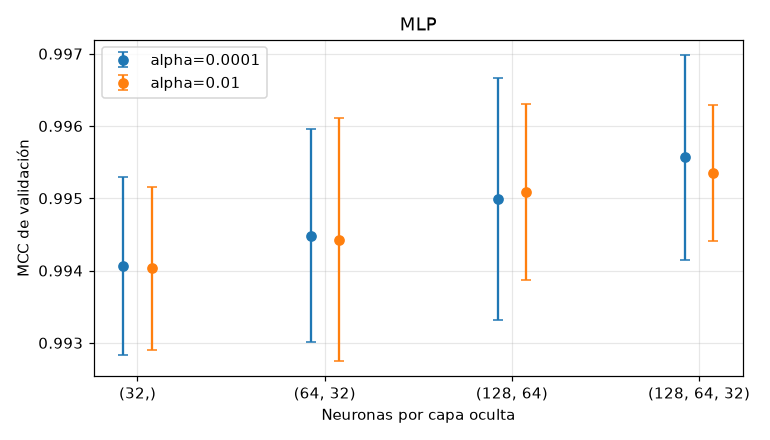

In [26]:
mlp = malla('MLP').copy()
mlp['Arquitectura'] = mlp['param_modelo__hidden_layer_sizes'].astype(str)
orden = sorted(mlp['Arquitectura'].unique(), key=len)
alfas = sorted(mlp['param_modelo__alpha'].unique())
ancho = .15
plt.figure(figsize=(7, 4))
for i, alfa in enumerate(alfas):
    parte = mlp[mlp['param_modelo__alpha'] == alfa].set_index('Arquitectura').loc[orden]
    plt.errorbar(np.arange(len(orden)) + i * ancho, parte['mean_test_mcc'], yerr=2 * parte['std_test_mcc'],
                 fmt='o', capsize=3, label=f'alpha={alfa}')
plt.xticks(np.arange(len(orden)) + ancho * (len(alfas) - 1) / 2, orden)
plt.xlabel('Neuronas por capa oculta')
plt.ylabel('MCC de validación')
plt.title('MLP')
plt.legend()
plt.grid(alpha=.3)
plt.tight_layout()
plt.savefig(FIGURAS / 'hiperparametros_mlp.png', dpi=200)
plt.show()

### Escenario completo

Se usan los mejores hiperparámetros del escenario solo URL con las mismas particiones. Sirve como punto de comparación
con la literatura.

In [27]:
def con_mejores(nombre):
    modelo = clone(MODELOS[nombre]['estimador'])
    mejores = {k: (tuple(v) if isinstance(v, list) else v) for k, v in RESUMEN[nombre]['mejores'].items()}
    return modelo.set_params(**mejores)


def evaluar_completo(nombre):
    idx = indices(MODELOS[nombre]['datos'])
    modelo = con_mejores(nombre)
    r = cross_validate(modelo, X.iloc[idx][COMPLETO], y[idx], groups=grupos[idx], cv=cv, scoring=METRICAS,
                       n_jobs=2, return_train_score=False)
    modelo.fit(X.iloc[idx][COMPLETO], y[idx])
    return {'mejores': RESUMEN[nombre]['mejores'],
            'entrenamiento': evaluar(modelo, COMPLETO, idx),
            'validacion': {m: float(r[f'test_{m}'].mean()) for m in METRICAS},
            'validacion_std': {m: float(r[f'test_{m}'].std()) for m in METRICAS},
            'prueba': evaluar(modelo, COMPLETO, idx_test)}


ruta = RESULTADOS / 'completo.json'
if ruta.exists() and not RECALCULAR:
    RESUMEN_COMPLETO = json.loads(ruta.read_text(encoding='utf-8'))
else:
    RESUMEN_COMPLETO = {}
    for nombre in MODELOS:
        print('Evaluando:', nombre, flush=True)
        RESUMEN_COMPLETO[nombre] = evaluar_completo(nombre)
    ruta.write_text(json.dumps(RESUMEN_COMPLETO, indent=2), encoding='utf-8')

tabla_completo = tabla_resultados(RESUMEN_COMPLETO)
tabla_completo.to_csv(RESULTADOS / 'tabla_completo.csv')
tabla_completo

,Exactitud val,F1 val,MCC val,AUC val,FPR val,MCC train,MCC test,FPR test
Modelo,,,,,,,,
Regresión logística,1.0000 ± 0.0001,1.0000 ± 0.0001,0.9999 ± 0.0001,1.0000 ± 0.0000,0.0000 ± 0.0000,0.9999,0.9998,0.0
KNN,0.9993 ± 0.0002,0.9992 ± 0.0002,0.9985 ± 0.0004,0.9992 ± 0.0002,0.0002 ± 0.0002,1.0000,0.9988,0.0
Random Forest,1.0000 ± 0.0000,1.0000 ± 0.0000,1.0000 ± 0.0001,1.0000 ± 0.0000,0.0000 ± 0.0000,1.0000,1.0000,0.0
MLP,0.9999 ± 0.0001,0.9999 ± 0.0001,0.9998 ± 0.0001,1.0000 ± 0.0000,0.0000 ± 0.0000,1.0000,0.9999,0.0
SVM,0.9999 ± 0.0003,0.9999 ± 0.0003,0.9999 ± 0.0005,1.0000 ± 0.0000,0.0001 ± 0.0002,1.0000,0.9999,0.0


### Comparación entre escenarios y matriz de confusión

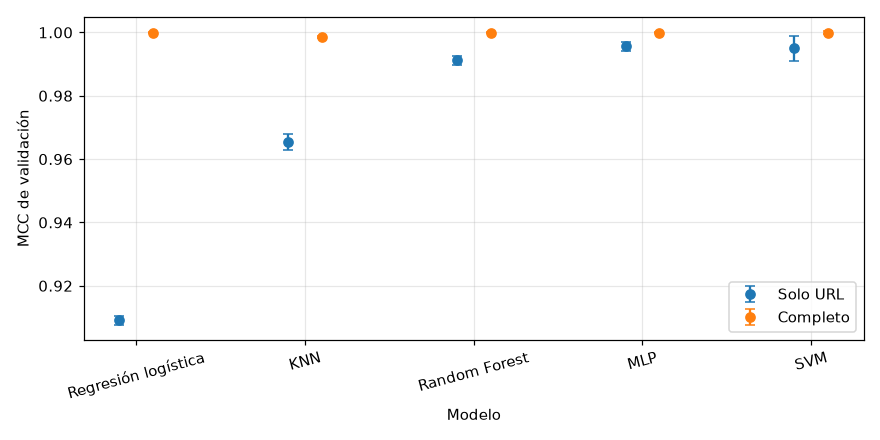

Dos mejores modelos según validación: ['MLP', 'SVM']


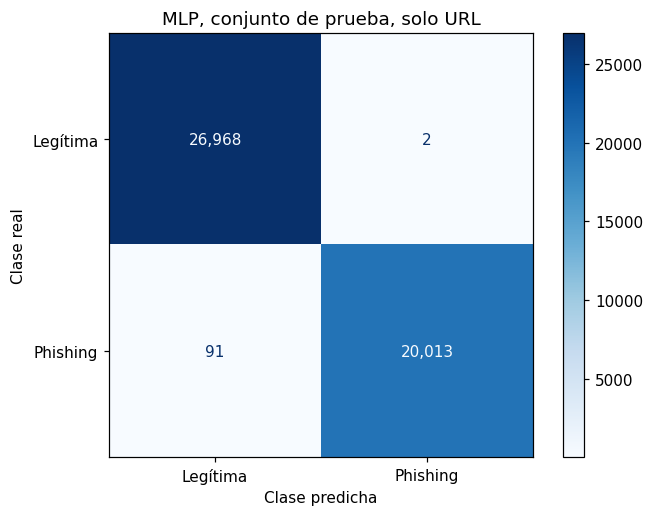

In [28]:
nombres = list(MODELOS)
pos = np.arange(len(nombres))
plt.figure(figsize=(8, 4))
for i, (etiqueta, datos) in enumerate({'Solo URL': RESUMEN, 'Completo': RESUMEN_COMPLETO}.items()):
    plt.errorbar(pos + (i - .5) * .2, [datos[n]['validacion']['mcc'] for n in nombres],
                 yerr=[2 * datos[n]['validacion_std']['mcc'] for n in nombres], fmt='o', capsize=3, label=etiqueta)
plt.xticks(pos, nombres, rotation=15)
plt.xlabel('Modelo')
plt.ylabel('MCC de validación')
plt.legend(loc='lower right')
plt.grid(alpha=.3)
plt.tight_layout()
plt.savefig(FIGURAS / 'comparacion_escenarios.png', dpi=200)
plt.show()

orden_val = sorted(nombres, key=lambda n: RESUMEN[n]['validacion']['mcc'], reverse=True)
MEJORES_2 = orden_val[:2]
print('Dos mejores modelos según validación:', MEJORES_2)
(RESULTADOS / 'dos_mejores.json').write_text(json.dumps(MEJORES_2, ensure_ascii=False), encoding='utf-8')

ganador = MEJORES_2[0]
modelo = con_mejores(ganador)
idx = indices(MODELOS[ganador]['datos'])
modelo.fit(X.iloc[idx][SOLO_URL], y[idx])
matriz = confusion_matrix(y[idx_test], modelo.predict(X.iloc[idx_test][SOLO_URL]))
ConfusionMatrixDisplay(matriz, display_labels=['Legítima', 'Phishing']).plot(values_format=',d', cmap='Blues')
plt.title(f'{ganador}, conjunto de prueba, solo URL')
plt.xlabel('Clase predicha')
plt.ylabel('Clase real')
plt.tight_layout()
plt.savefig(FIGURAS / 'matriz_confusion.png', dpi=200)
plt.show()